# Geostatistics: empirical semivariograms and variogram models
Companion to [notes/spatial_statistics/geostatistics.md](../../notes/spatial_statistics/geostatistics.md). We simulate a spatially correlated field, compute an empirical semivariogram by hand and in bulk, fit an exponential model, and check how trend and anisotropy distort it.

In [1]:
import numpy as np, matplotlib.pyplot as plt
from scipy.optimize import curve_fit
rng = np.random.default_rng(40)

## 1. The five-point hand example
The note's five points give $\hat\gamma(1)=19/10=1.9$. We confirm with code: collect all pairs at distance exactly 1, square the differences, and divide by $2|N(h)|$.

In [2]:
pts = np.array([[0,0],[1,0],[0,1],[1,1],[2,0]], float)
z5 = np.array([10,12,11,14,13], float)
i, j = np.triu_indices(len(z5), 1)
d = np.linalg.norm(pts[i]-pts[j], axis=1)
sel = np.isclose(d, 1.0)
sq = (z5[i]-z5[j])[sel]**2
print("pairs:", sel.sum(), "squared diffs:", sq, "sum:", sq.sum())
print("gamma_hat(1) =", sq.sum()/(2*sel.sum()))

pairs: 5 squared diffs: [4. 1. 4. 1. 9.] sum: 19.0
gamma_hat(1) = 1.9


## 2. Simulate a stationary field
We draw a Gaussian field with exponential covariance $C(h)=c\,e^{-h/a}$ plus a nugget, using a Cholesky factor, at 250 random locations in a $100\times100$ square. True parameters: nugget $0.4$, partial sill $2.6$, $a=12$ (practical range $36$).

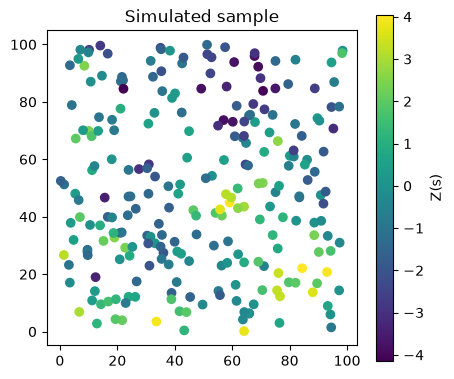

In [3]:
n = 250
xy = rng.uniform(0, 100, (n, 2))
D = np.linalg.norm(xy[:,None]-xy[None], axis=2)
c0_true, c_true, a_true = 0.4, 2.6, 12.0
Cov = c_true*np.exp(-D/a_true) + c0_true*np.eye(n)
z = np.linalg.cholesky(Cov) @ rng.standard_normal(n)
fig, ax = plt.subplots(figsize=(5,4.5))
s = ax.scatter(xy[:,0], xy[:,1], c=z, cmap='viridis'); plt.colorbar(s, label='Z(s)')
ax.set_title('Simulated sample'); ax.set_aspect('equal'); plt.show()

## 3. Empirical semivariogram with pair counts
Pairs are grouped into 5-unit lag bins up to 50 (half the maximum distance, a common rule of thumb). The counts matter: points with few pairs are unreliable.

In [4]:
def emp_variogram(xy, z, width=5, maxd=50):
    i, j = np.triu_indices(len(z), 1)
    d = np.linalg.norm(xy[i]-xy[j], axis=1)
    g = 0.5*(z[i]-z[j])**2
    edges = np.arange(0, maxd+width, width)
    idx = np.digitize(d, edges) - 1
    h, gam, cnt = [], [], []
    for b in range(len(edges)-1):
        m = idx == b
        if m.sum() > 0:
            h.append(d[m].mean()); gam.append(g[m].mean()); cnt.append(m.sum())
    return np.array(h), np.array(gam), np.array(cnt)
h, gam, cnt = emp_variogram(xy, z)
for a_, b_, c_ in zip(h, gam, cnt): print(f"h={a_:5.1f}  gamma={b_:5.2f}  pairs={c_}")

h=  3.2  gamma= 1.05  pairs=215
h=  7.7  gamma= 1.72  pairs=710
h= 12.7  gamma= 2.24  pairs=1034
h= 17.7  gamma= 2.48  pairs=1375
h= 22.6  gamma= 2.68  pairs=1671
h= 27.5  gamma= 3.10  pairs=1912
h= 32.5  gamma= 3.27  pairs=1989
h= 37.5  gamma= 2.97  pairs=2031
h= 42.5  gamma= 3.09  pairs=2130
h= 47.5  gamma= 3.24  pairs=2125


## 4. Fit an exponential model
We fit $\gamma(h)=c_0+c(1-e^{-h/a})$ by pair-count-weighted least squares (`sigma` $\propto 1/\sqrt{N}$). Compare with the true values and compute the practical range $3a$. One realization gives a noisy estimate: the nugget in particular is weakly identified.

fitted c0, c, a = [ 0.33  2.94 12.27]  practical range ~ 36.8
true   c0, c, a = (0.4, 2.6, 12.0)


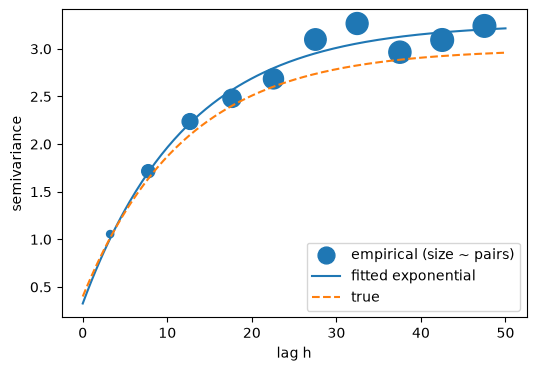

In [5]:
model = lambda h, c0, c, a: c0 + c*(1-np.exp(-h/a))
p, _ = curve_fit(model, h, gam, p0=[0.3, 2, 10], sigma=1/np.sqrt(cnt), bounds=(0, [10, 20, 100]))
print("fitted c0, c, a =", p.round(2), " practical range ~", round(3*p[2],1))
print("true   c0, c, a =", (c0_true, c_true, a_true))
hh = np.linspace(0, 50, 200)
fig, ax = plt.subplots(figsize=(6,4))
ax.scatter(h, gam, s=cnt/8, label='empirical (size ~ pairs)')
ax.plot(hh, model(hh, *p), label='fitted exponential')
ax.plot(hh, model(hh, c0_true, c_true, a_true), '--', label='true')
ax.set_xlabel('lag h'); ax.set_ylabel('semivariance'); ax.legend(); plt.show()

## 5. Covariance versus variogram models
Under second-order stationarity $\gamma(h)=C(0)-C(h)$. Below are the three standard families with the same sill and nominal $a$. The spherical model reaches the sill exactly at $a$, the exponential practical range is $3a$ and the Gaussian is $\sqrt3\,a$.

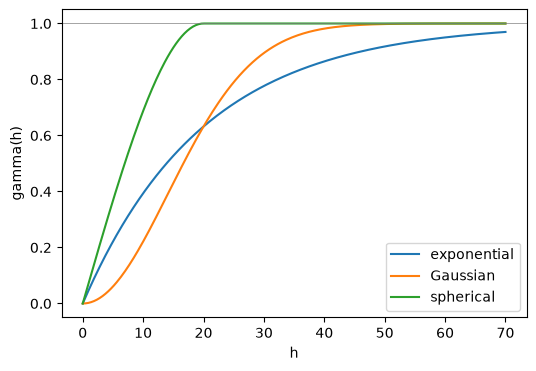

fraction of sill: exponential at 3a = 0.9502 ; Gaussian at sqrt(3)a = 0.9502 ; spherical at a = 1.0


In [6]:
c0, c, a = 0.0, 1.0, 20.0
hh = np.linspace(0, 70, 300)
exp_ = c0 + c*(1-np.exp(-hh/a))
gau = c0 + c*(1-np.exp(-(hh/a)**2))
sph = np.where(hh<=a, c0 + c*(1.5*hh/a - 0.5*(hh/a)**3), c0+c)
plt.figure(figsize=(6,4))
for y, l in ((exp_,'exponential'),(gau,'Gaussian'),(sph,'spherical')): plt.plot(hh, y, label=l)
plt.axhline(c0+c, color='gray', lw=.5); plt.legend(); plt.xlabel('h'); plt.ylabel('gamma(h)'); plt.show()
print("fraction of sill: exponential at 3a =", round(1-np.exp(-3),4),
      "; Gaussian at sqrt(3)a =", round(1-np.exp(-3),4), "; spherical at a =", 1.0)

## 6. A trend inflates the variogram
Adding a linear west-east trend to the same field makes the semivariogram keep rising with distance instead of leveling off. Removing the trend by least squares restores the sill.

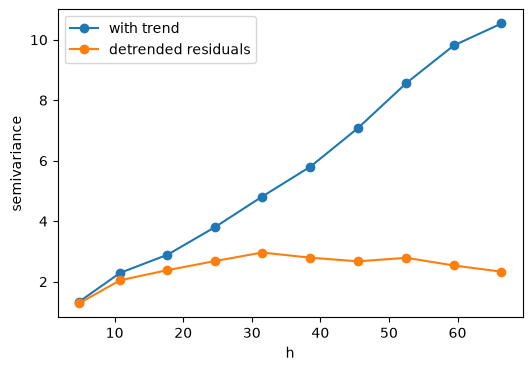

estimated trend slope in x: 0.082 (true 0.08)


In [7]:
zt = z + 0.08*xy[:,0]
X = np.c_[np.ones(n), xy]
beta = np.linalg.lstsq(X, zt, rcond=None)[0]
res = zt - X@beta
plt.figure(figsize=(6,4))
for lab, v in (('with trend', zt), ('detrended residuals', res)):
    hh_, gg_, _ = emp_variogram(xy, v, width=7, maxd=70)
    plt.plot(hh_, gg_, 'o-', label=lab)
plt.xlabel('h'); plt.ylabel('semivariance'); plt.legend(); plt.show()
print("estimated trend slope in x:", beta[1].round(3), "(true 0.08)")

## 7. Directional variograms
A geometric anisotropy is created by stretching the distance along y (so correlation decays faster north-south). Directional empirical variograms with a $\pm22.5^\circ$ tolerance reveal the difference that an omnidirectional variogram would hide.

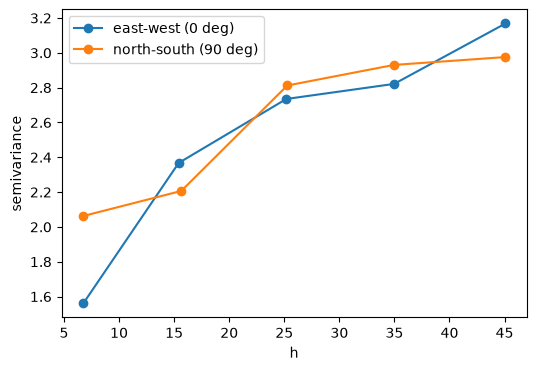

In [8]:
Da = np.sqrt((xy[:,None,0]-xy[None,:,0])**2 + (3*(xy[:,None,1]-xy[None,:,1]))**2)
za = np.linalg.cholesky(c_true*np.exp(-Da/a_true) + c0_true*np.eye(n)) @ rng.standard_normal(n)
i, j = np.triu_indices(n, 1)
dx, dy = xy[j,0]-xy[i,0], xy[j,1]-xy[i,1]
ang = np.degrees(np.arctan2(dy, dx)) % 180
dist = np.hypot(dx, dy); g = 0.5*(za[i]-za[j])**2
plt.figure(figsize=(6,4))
for lab, center in (('east-west (0 deg)', 0), ('north-south (90 deg)', 90)):
    dd = np.abs((ang-center+90) % 180 - 90)
    m = dd <= 22.5
    edges = np.arange(0, 60, 10); k = np.digitize(dist[m], edges)-1
    hs = [dist[m][k==b].mean() for b in range(5) if (k==b).any()]
    gs = [g[m][k==b].mean() for b in range(5) if (k==b).any()]
    plt.plot(hs, gs, 'o-', label=lab)
plt.xlabel('h'); plt.ylabel('semivariance'); plt.legend(); plt.show()

## Takeaways
- $\hat\gamma$ is half the average squared difference per bin; always inspect pair counts.
- The exponential fit recovers sill and scale approximately; practical range is $3a$.
- Detrend before reading a variogram, and compare directions before assuming isotropy.